In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('/kaggle/input/datasets/elemento/nyc-yellow-taxi-trip-data/yellow_tripdata_2016-03.csv')

In [3]:
df.shape

(12210952, 19)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12210952 entries, 0 to 12210951
Data columns (total 19 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   VendorID               int64  
 1   tpep_pickup_datetime   object 
 2   tpep_dropoff_datetime  object 
 3   passenger_count        int64  
 4   trip_distance          float64
 5   pickup_longitude       float64
 6   pickup_latitude        float64
 7   RatecodeID             int64  
 8   store_and_fwd_flag     object 
 9   dropoff_longitude      float64
 10  dropoff_latitude       float64
 11  payment_type           int64  
 12  fare_amount            float64
 13  extra                  float64
 14  mta_tax                float64
 15  tip_amount             float64
 16  tolls_amount           float64
 17  improvement_surcharge  float64
 18  total_amount           float64
dtypes: float64(12), int64(4), object(3)
memory usage: 1.7+ GB


In [5]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,1,2016-03-01 00:00:00,2016-03-01 00:07:55,1,2.50,-73.976746,40.765152,1,N,-74.004265,40.746128,1,9.0,0.5,0.5,2.05,0.00,0.3,12.35
1,1,2016-03-01 00:00:00,2016-03-01 00:11:06,1,2.90,-73.983482,40.767925,1,N,-74.005943,40.733166,1,11.0,0.5,0.5,3.05,0.00,0.3,15.35
2,2,2016-03-01 00:00:00,2016-03-01 00:31:06,2,19.98,-73.782021,40.644810,1,N,-73.974541,40.675770,1,54.5,0.5,0.5,8.00,0.00,0.3,63.80
3,2,2016-03-01 00:00:00,2016-03-01 00:00:00,3,10.78,-73.863419,40.769814,1,N,-73.969650,40.757767,1,31.5,0.0,0.5,3.78,5.54,0.3,41.62
4,2,2016-03-01 00:00:00,2016-03-01 00:00:00,5,30.43,-73.971741,40.792183,3,N,-74.177170,40.695053,1,98.0,0.0,0.0,0.00,15.50,0.3,113.80


DATA PREPROCESSING AND CLEANING

In [6]:
df['tpep_pickup_datetime']=pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime']=pd.to_datetime(df['tpep_dropoff_datetime'])

In [7]:
#Chceking for missing values across columns
print('Missing values per column:\n',df.isnull().sum())

Missing values per column:
 VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
pickup_longitude         0
pickup_latitude          0
RatecodeID               0
store_and_fwd_flag       0
dropoff_longitude        0
dropoff_latitude         0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
dtype: int64


In [8]:
#Sanity Check on data anomalies
print('Trips with passenger count 0:',(df['passenger_count']<=0).sum())
print('Trips with fare 0:',(df['fare_amount']<=0).sum())
print('Trips with distance 0:',(df['trip_distance']<=0).sum())
print('Trips where dropoff time is before pickup time:',(df['tpep_dropoff_datetime']<df['tpep_pickup_datetime']).sum())

Trips with passenger count 0: 608
Trips with fare 0: 8362
Trips with distance 0: 71126
Trips where dropoff time is before pickup time: 109


In [9]:
#Cleaning the dataset
df_clean = df[                        #when we use [], we are filtering row wise, so after cleaning the number of rows might decrease but the number of columns remain exact same.
(df['passenger_count']>0) &
(df['fare_amount']>0) &
(df['trip_distance']>0) &
(df['tpep_dropoff_datetime']>=df['tpep_pickup_datetime'])
].copy()

In [10]:
print(df_clean.shape)

(12133876, 19)


# PILLAR A

TARGET AND FEATURE PREPARATION

In [11]:
#PILLAR A: SURGE TIER CLASSIFICATION

#Calculating the trip duration
df_clean['trip_duration'] = (df_clean['tpep_dropoff_datetime']-df_clean['tpep_pickup_datetime']).dt.total_seconds()/60.0
# dt.total_seconds() / 60.0: Converts the pandas datetime difference into actual floating-point minutes so we know how long the trip took.
# In Pandas, .dt is the datetime accessor.

#Calculating the fare to distance ratio (as the ratio increases, the traffic increases)
df_clean['fare_per_distance'] = df_clean['fare_amount']/df_clean['trip_distance'] + 0.001 #0.001 is an epsilon that prevents divsion by zero.

#Calculating the hour and day of the week the trip started to study the traffic patterns
df_clean['pickup_hour'] = df_clean['tpep_pickup_datetime'].dt.hour
df_clean['pickup_day_of_week'] = df_clean['tpep_pickup_datetime'].dt.dayofweek

q70 = df_clean['fare_per_distance'].quantile(0.70)
q90 = df_clean['fare_per_distance'].quantile(0.90)

def assign_surge_tier(row):
    if row['fare_per_distance']>=q90:
        return 2   #Gridlock
    elif row['fare_per_distance']>=q70:
        return 1   #Heavy Traffic
    else:
        return 0   #Normal Traffic
#Applying the function for obtaining our targetted column
df_clean['surge_tiers']=df_clean.apply(assign_surge_tier,axis=1)

#Verification of the Distribution
print('Verification of the distribution:\n',df_clean['surge_tiers'].value_counts(normalize=True)*100)




Verification of the distribution:
 surge_tiers
0    69.934957
1    20.064949
2    10.000094
Name: proportion, dtype: float64


MODEL DEVELOPMENT

In [12]:
#Defining the exact columns to be looked into for the clues.
featured_cols = [
    'trip_duration',
    'trip_distance',
    'fare_amount',
    'fare_per_distance',
    'pickup_hour',
    'pickup_day_of_week',
    'passenger_count'
]

#Taking a sample of 1M rows instead of the original size of 12M rows
df_sample = df_clean.sample(n=1000000, random_state=42)

#Separating our features (X) from our target answer key (y)
X_sample = df_sample[featured_cols]
y_sample = df_sample['surge_tiers']

#Importing the toolkit
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

#Splitting the training and testing data
X_train,X_test,y_train,y_test = train_test_split(X_sample, y_sample, test_size=0.2, random_state=42, stratify=y_sample)

clf = RandomForestClassifier(
    n_estimators = 50, #builds 50 decision trees. 
    max_depth = 12, #how deep each tree is allowed to grow.
    random_state = 42, #uses the same random sequence every time.
    n_jobs = -1 #uses all available CPU cores. That way training becomes faster
    
)

# Training the model
clf.fit(X_train,y_train)

#Predicting and Grading
y_pred = clf.predict(X_test)
print('Classification Report:\n',classification_report(y_test,y_pred))
print('FI macro-score:\n',f1_score(y_test,y_pred,average='macro'))






Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    139893
           1       1.00      1.00      1.00     40155
           2       1.00      1.00      1.00     19952

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000

FI macro-score:
 0.9999946580775158


CROSS CHECKING THE MODEL WITHOUT THE LEAKAGE THIS TIME (MODEL EVALUATION AND PREDICTION)

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

#THE ONLY CHANGE, REMOVING FARE AMOUNT AND FARE PER DISTANCE COLUMNS
featured_cols = [
    'trip_distance',
    'passenger_count',
    'trip_duration',
    'pickup_hour',
    'pickup_day_of_week'
]

X_sample = df_sample[featured_cols]
y_sample = df_sample['surge_tiers']

X_train, X_test, y_train, y_test = train_test_split(X_sample, y_sample, test_size=0.2, random_state=42, stratify=y_sample)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

clf = RandomForestClassifier(
    n_estimators = 50,
    max_depth = 12,
    random_state = 42,
    n_jobs = -1
)

print('Training model without fare features...')
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print('\nTrue predictive classification report: \n', classification_report(y_test,y_pred))
print('\nTrue Macro-F1 Score:',f1_score(y_test, y_pred, average='macro'))

Training set shape: (800000, 5)
Testing set shape: (200000, 5)
Training model without fare features...

True predictive classification report: 
               precision    recall  f1-score   support

           0       0.98      0.99      0.99    139893
           1       0.92      0.94      0.93     40155
           2       0.97      0.93      0.95     19952

    accuracy                           0.97    200000
   macro avg       0.96      0.95      0.96    200000
weighted avg       0.97      0.97      0.97    200000


True Macro-F1 Score: 0.955708091714647


# PILLAR B

TARGET CONSTRUCTION

In [14]:
import numpy as np

epsilon = 0.0001

df_clean['cepi_score'] = (df_clean['trip_duration']/(df_clean['trip_distance']+epsilon))*df_clean['fare_per_distance']

print('CEPI Score summary statistics: \n',df_clean['cepi_score'].describe())



CEPI Score summary statistics: 
 count    1.213388e+07
mean     3.367376e+02
std      2.719742e+05
min      0.000000e+00
25%      1.818714e+01
50%      3.047862e+01
75%      5.016992e+01
max      7.188224e+08
Name: cepi_score, dtype: float64


In [15]:
# Calculating the 99th percentile threshold to identify extreme outliers
upper_limit = df_clean['cepi_score'].quantile(0.99)
print(f"99th percentile cap value: {upper_limit}")

# Clip/cap the cepi_score so nothing exceeds this safe limit
df_clean['cepi_score'] = df_clean['cepi_score'].clip(upper=upper_limit)

print('Cleaned CEPI Score summary statistics: \n',df_clean['cepi_score'].describe())



99th percentile cap value: 269.111672278339
Cleaned CEPI Score summary statistics: 
 count    1.213388e+07
mean     4.215695e+01
std      4.110116e+01
min      0.000000e+00
25%      1.818714e+01
50%      3.047862e+01
75%      5.016992e+01
max      2.691117e+02
Name: cepi_score, dtype: float64


FEATURE PREPARATION

In [16]:
# THIS STEP IS ALL ABOUT PROTECTING OUR DATA FROM LEAKAGE.

# Taking 1M rows from the cleaned dataset as sample for model training.
df_sample = df_clean.sample(n=1000000, random_state=42)

#Defining the feature columns (will remain same as that in the above (previous) code.)
featured_cols = [
    'trip_distance',
    'trip_duration',
    'passenger_count',
    'pickup_hour',
    'pickup_day_of_week'
]

X_sample = df_sample[featured_cols]
y_sample = df_sample['cepi_score']

print(f'X_sample shape (X): {X_sample.shape}')
print(f'y_sample shape (y): {y_sample.shape}')

X_sample shape (X): (1000000, 5)
y_sample shape (y): (1000000,)


MODEL DEVELOPMENT

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Splitting our sample data into training and testing sets (ratio, 8:2)
X_train, X_test, y_train, y_test = train_test_split(X_sample, y_sample, test_size=0.2, random_state=42)

# Training and Testing sets shape
print(f'training set shape: {X_train.shape}')
print(f'testing set shape: {X_test.shape}')

#Initializing the random forest regressor
reg = RandomForestRegressor(
    n_estimators = 50,
    max_depth = 12,
    random_state = 42,
    n_jobs = -1
)

print('\n training random forest regressor....')
reg.fit(X_train,y_train)
print('\ntraining complete!')



training set shape: (800000, 5)
testing set shape: (200000, 5)

 training random forest regressor....

training complete!


MODEL EVALUATION

In [18]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

#Generating the predictions for the test set 
y_pred = reg.predict(X_test)

#Calculating the evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'ROOT MEANS SQUARED ERROR: {rmse:.4f}')
print(f'R2 SCORE: {r2:.4f}')


ROOT MEANS SQUARED ERROR: 4.4140
R2 SCORE: 0.9884


PREDICTION GENERATION

In [19]:
import pandas as pd

# Generating the predictions for the test set
y_pred_sample = reg.predict(X_test)

# Building the comparision dataframe between the actual values and the predicted values.
comparision_df = X_test.copy()
comparision_df['actual_cepi'] = y_test
comparision_df['predicted_cepi'] = y_pred_sample

# Printing a random sample of 10 trips to see how close our model got.
print("Sample of Actual vs Predicted Carbon Emission & Penalty Index:")
print(comparision_df[['trip_distance','trip_duration','actual_cepi','predicted_cepi']].sample(10, random_state=42))



Sample of Actual vs Predicted Carbon Emission & Penalty Index:
          trip_distance  trip_duration  actual_cepi  predicted_cepi
8544239            1.00       4.300000    23.651935       23.149025
4348107            2.30      17.633333    43.339116       42.219535
10089348           1.14       5.750000    28.761370       26.329629
7180817            0.80       9.883333   123.538579      116.709125
3806820            6.20      33.266667    21.640466       21.865818
3875900            1.16       5.366667    23.932409       24.160373
6836891            3.45      14.666667    16.022830       16.504056
5759790            1.24      15.366667   104.940194      106.114670
5463632            2.84       9.250000    12.044715       11.684531
2426696            0.92      10.616667   100.347198       99.582835


# PILLAR C

ZONE UNDERSTANDING 

In [20]:
# Inspecting latitude and longitude stats to look out for outliers.
print('Pickup Latitude Stats:\n',df_clean['pickup_latitude'].describe())
print('Pickup Longitude Stats:\n',df_clean['pickup_longitude'].describe())

# Defining the bounding box cocrdinates for NYC core area
lat_min, lat_max = 40.55, 40.90
long_min, long_max = -74.05, -73.70

# Filtering our dataset to keep only trips that fall within this bounded box.
df_spatial = df_clean [
df_clean['pickup_latitude'].between(lat_min,lat_max) &
df_clean['pickup_longitude'].between(long_min,long_max) &
df_clean['dropoff_longitude'].between(long_min,long_max) &
df_clean['dropoff_latitude'].between(lat_min,lat_max)
].copy()

print(f'\nOriginal Number of Rows: {len(df_clean)}:,')
print(f'\nAfter filteration: {len(df_spatial)}:')



Pickup Latitude Stats:
 count    1.213388e+07
mean     4.018152e+01
std      4.783422e+00
min      0.000000e+00
25%      4.073644e+01
50%      4.075331e+01
75%      4.076768e+01
max      6.685682e+01
Name: pickup_latitude, dtype: float64
Pickup Longitude Stats:
 count    1.213388e+07
mean    -7.294020e+01
std      8.683144e+00
min     -1.616987e+02
25%     -7.399176e+01
50%     -7.398165e+01
75%     -7.396691e+01
max      0.000000e+00
Name: pickup_longitude, dtype: float64

Original Number of Rows: 12133876:,

After filteration: 11922870:


FEATURE ENGINEERING

In [21]:
# Extract pickup coordinates into a dedicated feature array for spatial clustering
coordinate_samples = df_spatial[['pickup_latitude','pickup_longitude']].sample(n=500000,random_state=42).values

print(f'SHAPE OF THE CLUSTERING FEATURE COORDINATES: {coordinate_samples.shape}')

SHAPE OF THE CLUSTERING FEATURE COORDINATES: (500000, 2)


CLUSTERING

In [22]:
from sklearn.cluster import KMeans

# Initializing k-means to find 20 major ghost corridors
print('Running k-means clustering on the coordinates.....')
kmeans = KMeans(n_clusters=20, random_state=42, n_init='auto')

#Model Fitting
kmeans.fit(coordinate_samples)

#Extracting the cluster center coordinates (which represents our core bottleneck hubs)
cluster_centers = kmeans.cluster_centers_

print('CLUSTERING COMPLETE!')
print(f'\nDiscovered {len(cluster_centers)} major bottlenecks/ghost corridors across New York City')



Running k-means clustering on the coordinates.....
CLUSTERING COMPLETE!

Discovered 20 major bottlenecks/ghost corridors across New York City


CLUSTER EVALUATION

In [23]:
import pandas as pd

# converting our cluster centers into a clean dataframe for inspection
df_clusters = pd.DataFrame(cluster_centers, columns = ['Latitude','Longitude'])

# Adding an index label to name each bottleneck hub
df_clusters.index.name = 'Hub-ID'

print("Bottleneck Locations discovered:")
print(df_clusters)

Bottleneck Locations discovered:
         Latitude  Longitude
Hub-ID                      
0       40.753361 -73.992010
1       40.646665 -73.784839
2       40.760021 -73.969945
3       40.770569 -73.869228
4       40.725747 -73.987457
5       40.795064 -73.968742
6       40.763870 -73.983802
7       40.780830 -73.952116
8       40.711177 -74.010340
9       40.741311 -74.002288
10      40.815465 -73.944448
11      40.749912 -73.977686
12      40.754719 -73.924198
13      40.663079 -73.948755
14      40.686307 -73.985811
15      40.779590 -73.980016
16      40.712434 -73.951986
17      40.739897 -73.987368
18      40.725910 -74.000995
19      40.770096 -73.959196


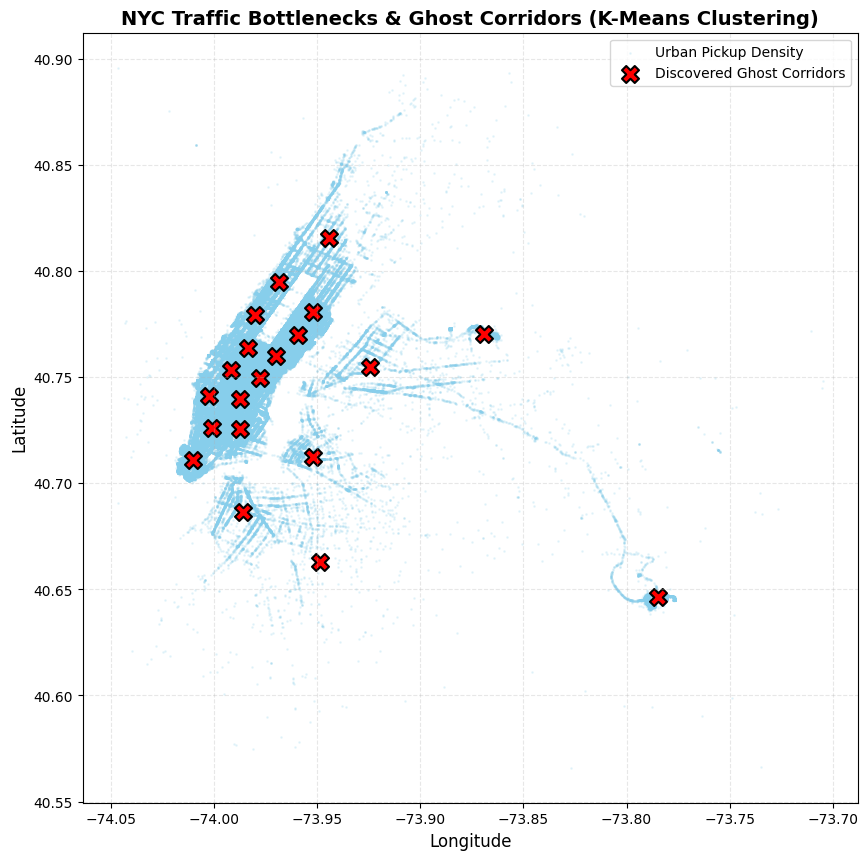

In [24]:
import matplotlib.pyplot as plt

# 1. Set up a large, high-resolution plot window
plt.figure(figsize=(10, 10))

# 2. Plot the 500,000 sampled pickup coordinates as a subtle background density map
plt.scatter(
    coordinate_samples[:, 1],  #passes longitude on the x-axis
    coordinate_samples[:, 0],  #passes latitude on the y-axis
    s=1,   #makes the dots tiny
    c='skyblue',  #sets the color of that dots to sky blue
    alpha=0.15,   #makes them heavily transparent
    label='Urban Pickup Density',
)

# 3. Plot our 20 K-Means cluster centers (Ghost Corridors) right on top as bold red X markers
plt.scatter(
    cluster_centers[:, 1],
    cluster_centers[:, 0],
    s=150,  #makes the markers large and prominent
    c='red', 
    marker='X',
    edgecolors='black',
    linewidths=1.5,
    label='Discovered Ghost Corridors',
)

# 4. Style the map with titles and labels
plt.title(
    'NYC Traffic Bottlenecks & Ghost Corridors (K-Means Clustering)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.3)

# 5. Save the figure locally into your notebook's file system
plt.savefig('nyc_ghost_corridors_map.png', dpi=300, bbox_inches='tight')

# 6. Render the visualization
plt.show()

CORRIDOR IDENTIFICATION

In [25]:
import pandas as pd

# Re-initializing df_clusters fresh from our K-Means centers to clear any accumulated merge/index baggage
df_clusters = pd.DataFrame(cluster_centers, columns=['Latitude', 'Longitude'])
df_clusters.index.name = 'Hub-ID'
df_clusters = df_clusters.reset_index()

# Assigning descriptive neighborhood labels to our discovered bottleneck hubs
def label_ghost_corridor(lat, lon):
    if 40.73 <= lat <= 40.78 and -74.00 <= lon <= -73.97:
        return "Midtown / Times Square Core"
    elif 40.70 <= lat <= 40.73 and -74.02 <= lon <= -73.99:
        return "Financial District / Lower Manhattan"
    elif 40.63 <= lat <= 40.66 and -73.80 <= lon <= -73.75:
        return "JFK Airport Transit Corridor"
    elif 40.76 <= lat <= 40.82 and -73.96 <= lon <= -73.93:
        return "Upper East Side / Bridge Approach"
    else:
        return "Urban Arterial Bottleneck / Side-Street Hub"

df_clusters['Corridor_Description'] = df_clusters.apply(lambda row: label_ghost_corridor(row['Latitude'], row['Longitude']), axis=1)

# Predicting cluster labels for our 500k sample coordinates
labels_assign = kmeans.predict(coordinate_samples)
df_sample_cluster = pd.DataFrame(coordinate_samples, columns=['latitude', 'longitude'])
df_sample_cluster['Hub-ID'] = labels_assign

# Computing spatial density counts per hub
hub_count = df_sample_cluster['Hub-ID'].value_counts().reset_index()
hub_count.columns = ['Hub-ID', 'Trip_Density_Count']

# Cleaning merge on 'Hub-ID' with zero duplicate risk
df_clusters = df_clusters.merge(hub_count, on='Hub-ID', how='left')

# Sorting hubs by density from highest to lowest volume
hubs_ranked = df_clusters.sort_values(by='Trip_Density_Count', ascending=False).reset_index(drop=True)

print("Top 5 Worst Traffic Ghost Corridors in NYC (Ranked by Volume & Friction):")
print(hubs_ranked[['Hub-ID', 'Corridor_Description', 'Trip_Density_Count', 'Latitude', 'Longitude']].head(5))


Top 5 Worst Traffic Ghost Corridors in NYC (Ranked by Volume & Friction):
   Hub-ID                         Corridor_Description  Trip_Density_Count  \
0       0                  Midtown / Times Square Core               49853   
1       2  Urban Arterial Bottleneck / Side-Street Hub               47720   
2       6                  Midtown / Times Square Core               46262   
3      17                  Midtown / Times Square Core               43667   
4      11                  Midtown / Times Square Core               43110   

    Latitude  Longitude  
0  40.753361 -73.992010  
1  40.760021 -73.969945  
2  40.763870 -73.983802  
3  40.739897 -73.987368  
4  40.749912 -73.977686  


# INTEGRATION OF ALL THREE PILLARS

In [42]:
# importing the libraries
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, f1_score, mean_squared_error


# Sampling and Assigning Ghost Corridor Hubs
integrated_df = df_spatial.sample(n=100000, random_state=42).copy()

pickup_coords = integrated_df[['pickup_latitude','pickup_longitude']].values
integrated_df['Hub-ID'] = kmeans.predict(pickup_coords)

print("Sampled rows:", len(integrated_df))
print(integrated_df[['pickup_latitude', 'pickup_longitude', 'Hub-ID']].head())



Sampled rows: 100000
          pickup_latitude  pickup_longitude  Hub-ID
10023421        40.740936        -74.007294       9
1066972         40.756779        -73.972176       2
2629950         40.646816        -73.781891       1
9062771         40.731682        -73.991554       4
9096370         40.775360        -73.953506       7


In [45]:
# Generating Surge Tier (Pillar A) and CEPI Score (Pillar B) predictions

# the order of the columns while fitting a model matters. The order was different in featured columns for both pillars A and B and in order to predict output, we need to use that same respecttive order.
featured_cols_for_st = [
    'trip_distance',
    'passenger_count',
    'trip_duration',
    'pickup_hour',
    'pickup_day_of_week'
]
featured_cols_for_cepi = [
    'trip_distance',
    'trip_duration',
    'passenger_count',
    'pickup_hour',
    'pickup_day_of_week'
]



X_telemetry = integrated_df[featured_cols_for_st]
Y_telemetry = integrated_df[featured_cols_for_cepi]
integrated_df['predicted_surge_tiers '] = clf.predict(X_telemetry)
integrated_df['predicted_cepi_score'] = reg.predict(Y_telemetry)

print(integrated_df[['Hub-ID','surge_tiers','predicted_surge_tiers','cepi_score','predicted_cepi_score']].head())


          Hub-ID  surge_tiers  predicted_surge_tiers  cepi_score  \
10023421       9            2                      2   72.117455   
1066972        2            0                      0   47.868258   
2629950        1            0                      0    5.380408   
9062771        4            2                      2  161.439779   
9096370        7            0                      0   12.438138   

          predicted_cepi_score  
10023421             68.160392  
1066972              46.743378  
2629950               5.410708  
9062771             169.680991  
9096370              12.791721  


In [51]:
# Validating integrated predictions and checking sample metrics 

assert len(integrated_df)==100000, "Rows count mismatch."
assert set(integrated_df['predicted_surge_tiers'].unique()).issubset({0,1,2}), "Invalid surge tier values"
assert (integrated_df['predicted_cepi_score']>=0).all(), "Negative CEPI Score value detected"

new_f1 = f1_score(integrated_df['surge_tiers'], integrated_df['predicted_surge_tiers'],average='macro')
new_rsme = np.sqrt(mean_squared_error(integrated_df['cepi_score'],integrated_df['predicted_cepi_score']))
new_r2_score = r2_score(integrated_df['cepi_score'],integrated_df['predicted_cepi_score'])

print("=== VALIDATION PASSED ===")
print(f"Sample Macro-F1: {new_f1:.4f}")
print(f"Sample RMSE:     {new_rsme:.4f}")
print(f"Sample R2:       {new_r2_score:.4f}")


=== VALIDATION PASSED ===
Sample Macro-F1: 0.9550
Sample RMSE:     3.9610
Sample R2:       0.9906


In [62]:
# Flag predicted Tier 2 gridlock and aggregate metrics per Ghost Corridor (Hub-ID)
integrated_df['is_gridlock_pred'] = (integrated_df['predicted_surge_tiers']==2).astype(int)

corridor_summary = (
    integrated_df.groupby('Hub-ID',as_index = 'False')
    .agg(
        trip_count = ('Hub-ID','count'),
        Average_predicted_cepi = ('predicted_cepi_score','mean'),
        Total_predicted_cepi = ('predicted_cepi_score','sum'),
        Gridlock_rate_prediction = ('is_gridlock_pred', lambda s: s.mean() * 100),
    )
)
print(corridor_summary.sort_values(by='Total_predicted_cepi', ascending=False).head(10).to_string(index=False))

 trip_count  Average_predicted_cepi  Total_predicted_cepi  Gridlock_rate_prediction
      10004               48.087864         481070.988454                 11.265494
       9330               50.592994         472032.638650                 14.201501
       9392               50.179633         471287.114744                 13.138842
       8653               52.240279         452035.138326                 14.908124
       8777               47.627874         418029.850583                 10.652843
       7141               44.087567         314829.317799                 10.964851
       6741               41.387275         278991.621809                  7.906839
       6459               38.966009         251681.452000                  7.710172
       5980               40.145949         240072.774735                  7.173913
       6084               37.932802         230783.168168                  8.234714


In [63]:
# Attaching hub coordinates/labels and ranking corridors
base_hubs = df_clusters[
    ['Hub-ID', 'Latitude', 'Longitude', 'Corridor_Description']
].drop_duplicates(subset=['Hub-ID'])

final_corridor_df = (
    base_hubs.merge(corridor_summary, on='Hub-ID', how='left')
    .sort_values(by='Total_predicted_cepi', ascending=False)
    .reset_index(drop=True)
)

print(
    final_corridor_df[[
        'Hub-ID',
        'Corridor_Description',
        'trip_count',
        'Average_predicted_cepi',
        'Total_predicted_cepi',
        'Gridlock_rate_prediction',
    ]]
    .head(10)
    .to_string(index=False)
)

 Hub-ID                        Corridor_Description  trip_count  Average_predicted_cepi  Total_predicted_cepi  Gridlock_rate_prediction
      0                 Midtown / Times Square Core       10004               48.087864         481070.988454                 11.265494
      2 Urban Arterial Bottleneck / Side-Street Hub        9330               50.592994         472032.638650                 14.201501
      6                 Midtown / Times Square Core        9392               50.179633         471287.114744                 13.138842
     11                 Midtown / Times Square Core        8653               52.240279         452035.138326                 14.908124
     17                 Midtown / Times Square Core        8777               47.627874         418029.850583                 10.652843
     19           Upper East Side / Bridge Approach        7141               44.087567         314829.317799                 10.964851
      9 Urban Arterial Bottleneck / Side-Street 